# 05．Event Engine：明列資料、計算結果與狀態寫入

本單元先讀取舊快照，呼叫 04 的能量核心取得結果，再由引擎寫入新狀態，最後回傳固定時點的快照副本。
閱讀順序為「事件佇列 → 三組資料 → 情境準備 → 計算／提交 → 示範 → 輪末出圖與清理」。

本次依已確認的模組化設計修正，尚待您逐段人工 trace。
RF、Paging／等待與接收結果仍為明列的研究輸入；完整 Access、服務記帳與 Baseline 不在本單元。


## 1．載入既有核心

03 的資源時序與 04 的電量核心都由 `src` 匯入；不執行其他 Notebook 的展示。
Engine 原型仍留在本 Notebook，待人工接受後才考慮抽離。

來源：[能量核心](../src/energy/tag_energy.py)、[完整程式 trace](../docs/architecture/event-engine/code-trace.md)。


In [ ]:
from pathlib import Path
import sys
import heapq
from dataclasses import dataclass, field
from types import MappingProxyType # can't mod the dict function
from typing import Mapping

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent

if not (ROOT / 'src').is_dir():
    raise ValueError('Run from the project root or notebooks directory')

# Add dependent varable
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

# from src
from timeline.contracts import ResourceConfig, UEDirection, ResourceWindow, NodeResource
from timeline.resource_timeline import build_timeline

from energy import tag_energy as energy


## 2．整數 ns 的同時事件批次

`heapq` 只管理時間與插入序號；插入序號不決定資料資格。同一時間的事件會一次取出。
過去時間、bool 或非整數時間會在插入前拒絕。


### 2.1．取出同時事件：pop_batch

事件佇列會依時間保存待處理事件。
一批事件指時間相同的所有事件。
第 1 行若為否，佇列直接回傳空值。

圖中編號對應下方虛擬碼。編號不代表 Python 原始碼行號。

```text
1. 佇列還有事件嗎？
2. 佇列將時鐘移到最早事件時間
3. 佇列取出該時間的所有事件
4. 佇列回傳時間與該批事件
```




In [ ]:
@dataclass(frozen=True)
class Event:
    time_ns: int
    kind: str # store the status type : example -> 'D2R_Refiction ' , paging
    payload: object


class EventQueue:
    def __init__(self):
        self.now_ns = 0
        self._events = []
        self._sequence = 0

    def schedule(self, time_ns, kind, payload=None):
        if type(time_ns) is not int or time_ns < 0:
            raise ValueError('event time must be nonnegative integer ns')

        if time_ns < self.now_ns:
            raise ValueError('cannot schedule an event in the past')

        if not isinstance(kind, str) or not kind.strip():
            raise ValueError('event kind must be a nonempty string')

        event = Event(time_ns, kind, payload)
        heapq.heappush(self._events, (time_ns, self._sequence, event)) # time first compare condtion ; sequence is second condition
        self._sequence += 1

    def peek_time(self): # look up next even time
        return self._events[0][0] if self._events else None

    def pop_batch(self): # get the first front all time even 
        if not self._events:
            return None
        
        self.now_ns = self._events[0][0]
        events = []
        
        while self._events and self._events[0][0] == self.now_ns:
            events.append(heapq.heappop(self._events)[2])
        return self.now_ns, tuple(events)


## 3．先明列資料與驗證責任

`OperationRequest` 明列外層選定操作；`BatchCW` 明列本批 CW 身分、共同終點與距離。
時間使用整數 ns；Tag 電量使用 J、RF 使用 W。時間／ID 的基本檢查屬於 Engine 輸入。
能量設定、快照與 RF 數值則由 04 的 `validate_energy_inputs()` 整批驗證。


In [3]:
def require_nonnegative_ns(value, name):
    if type(value) is not int or value < 0:
        raise ValueError(f'{name} must be a non-negative integer ns value')
    return value


@dataclass(frozen=True)
class OperationRequest:
    start_ns: int
    tag_id: str
    window_id: int
    tbs_bytes: int
    paging_ns: int
    wait_ns: int
    deadline_ns: int
    receive_success: bool = True
    cw_available: bool = True
    batch_id: str | None = None

    def __post_init__(self):
        if not isinstance(self.tag_id,str) or not self.tag_id.strip():
            raise ValueError('tag_id must be a nonempty string')

        if self.batch_id is not None and (not isinstance(self.batch_id, str) or not self.batch_id.strip()):
            raise ValueError('batch_id must be a nonempty string')

        require_nonnegative_ns(self.window_id,'window_id')
        require_nonnegative_ns(self.start_ns,'start_ns')


@dataclass(frozen=True)
class BatchCW:
    batch_id: str
    node_id: str
    window_id: int
    cw_off_ns: int
    cw_power_dbm: float
    tag_distances_m: tuple


### 3.1．三個 dataclass，各有一種資料責任

| 資料 | 用途 | 誰負責更新 |
|---|---|---|
| EngineScenario | 已準備的 Windows、Tag 歸屬、RF 與 batch 索引 | 準備函式回傳；字典使用唯讀檢視 |
| EngineState | 目前時鐘、快照、資源階段與尚未結束的操作 | Engine 明確寫入 |
| EngineRecords | 當窗 trace、本輪完成結果與各窗起訖摘要 | Engine 明確追加／清理 |

`default_factory` 為每個引擎建立自己的可變容器。
`active` 保存通過准入的計畫直到 Guard 結束，並非只代表 BACKSCATTER。
`window_starts` 暫存尚未結束的 Window 起點，不能在輪末誤清除。


In [4]:
@dataclass(frozen=True)
class EngineScenario:
    windows: tuple[ResourceWindow, ...]
    tag_nodes: Mapping[str, str]
    rf_inputs_w: Mapping[tuple[int, str], float]
    resources: Mapping[tuple[int, str], NodeResource]
    batches: Mapping[str, BatchCW]
    batch_requests: Mapping[str, tuple[OperationRequest, ...]]
    requests: tuple[OperationRequest, ...]


@dataclass
class EngineState:
    snapshots: dict[str, energy.TagSnapshot]
    now_ns: int = 0
    active: dict[str, energy.TagTrace] = field(default_factory=dict)
    phases: dict[str, str] = field(default_factory=dict)
    current_windows: dict[str, int | None] = field(default_factory=dict)
    cw_rf_w: dict[str, float] = field(default_factory=dict)


@dataclass
class EngineRecords:
    trace: list[dict[str, object]] = field(default_factory=list)
    completion_batches: list[tuple[int, tuple[dict[str, str | bool], ...]]] = field(default_factory=list)
    window_summaries: list[dict[str, str | int | float]] = field(default_factory=list)
    window_starts: dict[tuple[int, str], energy.TagSnapshot] = field(default_factory=dict)


### 3.2．準備資源關係

此函式只檢查並回傳資源索引，不建立佇列、不更新 Tag。
先檢查 Node 歸屬與 Windows 順序，再確認各 Node 時序與每個 Tag／Window 的 UE-prefix RF 輸入。
RF 資料齊全不等於 batch CW 可用；CW 仍由下一節的明確 batch 輸入控制。


In [5]:
def prepare_resources(windows, tag_nodes, rf_inputs_w):
    resources = {}
    node_ids = {node.node_id for window in windows for node in window.nodes} # R
    
    if not set(tag_nodes.values()) <= node_ids:
        raise ValueError('unknown serving Node')

    previous_end = -1
    
    for window in windows:
        if window.start_ns < previous_end: # prvious_end = last windows end
            raise ValueError('Windows must be ordered without overlap')
        previous_end = window.end_ns

        for node in window.nodes:
            if not node.start_ns < node.ue_end_ns < node.ue_end_ns+1_000_000 < node.end_ns:
                raise ValueError('resource must contain UE, switch and Tag intervals')
            resources[(node.window_id,node.node_id)] = node

            # UE-prefix RF input is required; batch CW is supplied separately.
            for tag_id, owner in tag_nodes.items():
                if owner == node.node_id:
                    key = (node.window_id,tag_id) # primary key
                    if key not in rf_inputs_w:
                        raise ValueError('missing per-Tag/window RF input')

    return resources


### 3.3．準備明確 batch

先按明列的 batch_id 分組，再檢查各批成員、不可變距離資料與共同 CW_OFF。
共同終點須等於最後一筆完整 D2R 的結束；相同起點本身不會建立 batch。
函式回傳已核對的索引，不扣能、不排入事件。非法資料以 ValueError 拒絕。


In [6]:
def validate_batch(batch, members, resources, tag_nodes):
    if not members:
        raise ValueError('batch must have selected members')

    if len({request.tag_id for request in members}) != len(members):
        raise ValueError('duplicate Tag in batch')

    # This prototype admits one supplied Paging start for a complete batch.
    if len({request.start_ns for request in members}) != 1:
        raise ValueError('batch members require one supplied Paging start')

    require_nonnegative_ns(batch.window_id, 'window_id')
    require_nonnegative_ns(batch.cw_off_ns, 'cw_off_ns')
    if not isinstance(batch.node_id, str) or (batch.window_id, batch.node_id) not in resources:
        raise ValueError('unknown batch Node or Window')

    if not isinstance(batch.tag_distances_m, tuple) or any(
            not isinstance(pair, tuple) or len(pair) != 2 or not isinstance(pair[0], str)
            for pair in batch.tag_distances_m):
        raise ValueError('batch distances must be a tuple of Tag/distance pairs')
    distances = dict(batch.tag_distances_m)
    if len(distances) != len(batch.tag_distances_m) or set(distances) != {request.tag_id for request in members}:
        raise ValueError('batch distances must match selected members exactly')
    ends = []
    for request in members:
        if tag_nodes.get(request.tag_id) != batch.node_id or request.window_id != batch.window_id:
            raise ValueError('batch member has a different Node or Window')

        if type(request.tbs_bytes) is not int or request.tbs_bytes not in energy.D2R_OCCUPANCY_NS:
            raise ValueError('invalid batch TBS')
        require_nonnegative_ns(request.paging_ns, 'paging_ns')
        require_nonnegative_ns(request.wait_ns, 'wait_ns')
        ends.append(request.start_ns + request.paging_ns + request.wait_ns + energy.D2R_OCCUPANCY_NS[request.tbs_bytes])
        energy.cw_rf_input_w(cw_power_dbm=batch.cw_power_dbm, distance_m=distances[request.tag_id])
    if batch.cw_off_ns != max(ends):
        raise ValueError('batch CW_OFF must equal the final complete D2R')
    return batch


def prepare_batches(requests, batches, resources, tag_nodes):
    batch_requests = {}
    batch_by_id = {}
    for request in requests:
        if not isinstance(request, OperationRequest):
            raise ValueError('requests must be OperationRequest values')

        if request.batch_id is not None:
            batch_requests.setdefault(request.batch_id, []).append(request)
    for batch in batches:
        if not isinstance(batch, BatchCW) or not isinstance(batch.batch_id, str) or not batch.batch_id.strip():
            raise ValueError('batches must contain named BatchCW values')

        if batch.batch_id in batch_by_id:
            raise ValueError('duplicate batch identity')
        members = batch_requests.get(batch.batch_id, [])
        batch_by_id[batch.batch_id] = validate_batch(batch, members, resources, tag_nodes)
    if set(batch_requests) != set(batch_by_id):
        raise ValueError('missing explicit batch CW declaration')
    return batch_by_id, {key:tuple(value) for key,value in batch_requests.items()}


### 3.4．組合已準備情境

`prepare_scenario()` 明列前兩節的呼叫順序，回傳 EngineScenario。
能量整批驗證在引擎建構時執行，通過全部初始檢查後才排入事件。
快照與輸入容器保持獨立；不以驗證之名呼叫零時長操作來產生假紀錄。


In [7]:
def prepare_scenario(windows, tag_nodes, rf_inputs_w, requests=(), *, batches=()):
    """Prepare relationships without state/queue writes; energy validates at construction."""
    windows = tuple(windows)
    tag_nodes = dict(tag_nodes)
    rf_inputs_w = dict(rf_inputs_w)
    requests = tuple(requests)
    if not windows or not tag_nodes:
        raise ValueError('nonempty windows and Tag inputs are required')
    resources = prepare_resources(windows, tag_nodes, rf_inputs_w)
    batch_by_id, batch_requests = prepare_batches(requests, tuple(batches), resources, tag_nodes)
    return EngineScenario(windows, MappingProxyType(tag_nodes), MappingProxyType(rf_inputs_w),
                          MappingProxyType(resources), MappingProxyType(batch_by_id),
                          MappingProxyType(batch_requests), requests)


## 4．計算回傳值，引擎負責寫入

`energy.project_tag_operation()` 沿用既有計畫內的時間投影與數值保護；中途觀察不會截斷 TBS。
背景、CW 尾段與 Guard 仍使用 `advance_tag_interval()`，保留耗盡與容量邊界。
下面的 `collect_completions()` 只回傳同時完成結果，不修改 state 或 records。


In [8]:
def collect_completions(events, time_ns):
    completed = []
    for event in events:
        if event.kind == 'D2R_END':
            request = event.payload
            completed.append(dict(tag_id=request.tag_id, receive_success=request.receive_success,
                                  eligible=request.receive_success and time_ns < request.deadline_ns))
    completed.sort(key=lambda row:row['tag_id'])
    return tuple(completed)


### 4.1．推進引擎：run_until

引擎使用整數奈秒（ns）表示時間。
階段指 Tag 當時所處的資源區段。
D2R 指 Tag 向 Reader 回傳資料。
Deadline 是資料完成期限。
完成時間必須嚴格早於 Deadline。
第 2 行若為否，引擎執行第 9 行。
第 8 行完成後，引擎重查第 2 行。

圖中編號對應下方虛擬碼。編號不代表 Python 原始碼行號。

```text
1. 引擎驗證停止時間不早於現在
2. 下一批事件在停止時間內嗎？
3. 佇列取出最早時間的整批事件
4. 引擎依舊階段結算各 Tag 電量
5. 引擎收集 D2R 完成與期限資格
6. 引擎更新資源階段與操作結束狀態
7. 引擎拒絕同一 Tag 的同時衝突請求
8. 引擎逐一檢查其餘新請求
9. 引擎推進至停止時間並回傳快照
```




### 4.2．檢查新操作：_request

准入指引擎允許操作開始。
快照記錄某時刻的 Tag 狀態與電量。
CW 是供 Tag 回傳使用的連續載波。
04 會檢查電量、時間與 CW 條件。
第 1 行檢查 Tag、窗口與忙碌狀態。
第 3 行若為否，引擎記錄拒絕後返回。

圖中編號對應下方虛擬碼。編號不代表 Python 原始碼行號。

```text
1. 引擎檢查 Tag 與目前資源
2. 04 檢查完整操作並產生計畫
3. 前兩行的檢查都通過嗎？
4. 引擎保存計畫並記錄喚醒
5. 引擎排入各操作階段的結束事件
6. 引擎更新當下快照
```




### 4.3．逐個閱讀引擎方法

| 方法 | 閱讀重點 |
|---|---|
| __init__ | 整批驗證後，建立獨立 state／records，最後才排入事件 |
| _advance | 讀取 previous → 呼叫計算 → 明確寫回 snapshots |
| _plan／_request_batch | 先準備完整計畫，全部通過才提交 |
| _admit | 寫入 active、追加紀錄、排入操作事件 |
| _apply_boundaries | 更新資源；在真實 Window 邊界擷取起訖快照 |
| run_until | 推進 → 收集完成 → 更新邊界 → 處理請求 |
| finish_round | 外層成功使用結果後，才移除已消費紀錄 |

當下快照只顯示當下電量；完整計畫不會被提前當成已執行結果。
`trace` 在下一個 Window 開始時取代上一窗內容；`window_summaries` 與完成結果保留到本輪消費。
外層使用或出圖失敗會保留紀錄；清理不重設電池、時鐘、active 或佇列。


In [9]:
# diss how to reduce
class TagEventEngine:
    """Own runtime commits; calculation helpers return values."""
    def __init__(self, scenario, initial_state):
        if not isinstance(scenario, EngineScenario) or not isinstance(initial_state, EngineState):
            raise ValueError('prepared scenario and EngineState are required')
        checked = energy.validate_energy_inputs(snapshots=initial_state.snapshots,
                                                rf_inputs_w=dict(scenario.rf_inputs_w))
        snapshots = checked['snapshots']
        if set(snapshots) != set(scenario.tag_nodes) or not snapshots:
            raise ValueError('matching nonempty Tag inputs are required')

        if initial_state.now_ns != 0 or type(initial_state.now_ns) is not int or any(
                (initial_state.active, initial_state.phases, initial_state.current_windows, initial_state.cw_rf_w)):
            raise ValueError('initial runtime state must start at zero without active work')
        for tag_id, snapshot in snapshots.items():
            if snapshot.tag_id != tag_id or snapshot.now_ns != 0 or snapshot.mode not in energy.INACTIVE_MODES:
                raise ValueError('initial snapshots must match IDs, be inactive and start at zero')
        self.scenario = scenario
        nodes = {node.node_id for window in scenario.windows for node in window.nodes}
        self.state = EngineState(snapshots=snapshots, phases={node:'GAP' for node in nodes},
                                 current_windows={node:None for node in nodes})
        self.records = EngineRecords()
        self.queue = EventQueue()
        self._schedule_initial_events()

    def _schedule_initial_events(self):
        for window in self.scenario.windows:
            for node in window.nodes:
                for time_ns, kind in ((node.start_ns,'WINDOW_START'),(node.ue_end_ns,'UE_END'),
                                      (node.ue_end_ns+1_000_000,'SWITCH_END'),(node.end_ns,'WINDOW_END')):
                    self.queue.schedule(time_ns,kind,node)
        for request in self.scenario.requests:
            self.queue.schedule(request.start_ns,'REQUEST',request)

    def _advance(self, time_ns):
        for tag_id, previous in self.state.snapshots.items():
            if tag_id in self.state.active:
                plan = self.state.active[tag_id]
                updated = energy.project_tag_operation(plan, now_ns=time_ns,
                                                        cw_rf_input_w=self.state.cw_rf_w.get(tag_id,0.0))
            else:
                node_id = self.scenario.tag_nodes[tag_id]
                window_id = self.state.current_windows[node_id]
                phase = self.state.phases[node_id]
                rf = self.scenario.rf_inputs_w[(window_id,tag_id)] if phase in ('UE_UL','UE_DL') else 0.0
                result = energy.advance_tag_interval(previous, duration_ns=time_ns-previous.now_ns,
                                                     phase=phase, rf_input_w=rf)
                updated = result.snapshot
            self.state.snapshots[tag_id] = updated
        self.state.now_ns = time_ns
        self.queue.now_ns = time_ns

    def _record(self, kind, tag_id=None, outcome='', **fields):
        row = dict(time_ns=self.state.now_ns,kind=kind,tag_id=tag_id,outcome=outcome,**fields)
        self.records.trace.append(row)

    def _plan(self, request, batch=None):
        tag_id = request.tag_id
        if tag_id not in self.state.snapshots:
            raise ValueError('unknown Tag')

        node_id = self.scenario.tag_nodes[tag_id]
        key = (request.window_id,node_id)
        if key not in self.scenario.resources or self.state.current_windows[node_id] != request.window_id:
            raise ValueError('operation Window is not current')

        node = self.scenario.resources[key]
        if self.state.now_ns < node.ue_end_ns+1_000_000 or self.state.now_ns >= node.end_ns:
            raise ValueError('operation starts outside Tag availability')

        if tag_id in self.state.active:
            raise ValueError('Tag already has an active operation')

        cw = {}
        if batch is not None:
            cw = dict(cw_off_ns=batch.cw_off_ns, cw_power_dbm=batch.cw_power_dbm,
                      distance_m=dict(batch.tag_distances_m)[tag_id])
        plan = energy.trace_tag_operation(self.state.snapshots[tag_id],tbs_bytes=request.tbs_bytes,
                    paging_ns=request.paging_ns,wait_ns=request.wait_ns,window_end_ns=node.end_ns,
                    deadline_ns=request.deadline_ns,receive_success=request.receive_success,cw_available=request.cw_available, **cw)
        return plan

    def _request(self, request):
        try:
            plan = self._plan(request)
        except ValueError as error:
            self._record('REJECTED', request.tag_id, str(error))
            return
        self._admit(request, plan)

    def _request_batch(self, requests, batch):
        # Prepare all members before debit; a refused member must not prolong CW.
        try:
            plans = [self._plan(request, batch) for request in requests]
        except ValueError as error:
            for request in requests:
                self._record('REJECTED', request.tag_id, str(error))
            return
        for request, plan in zip(requests, plans, strict=True):
            self.state.cw_rf_w[request.tag_id] = energy.cw_rf_input_w(
                cw_power_dbm=batch.cw_power_dbm, distance_m=dict(batch.tag_distances_m)[request.tag_id])
            self._admit(request, plan)
        self.queue.schedule(batch.cw_off_ns, 'CW_OFF', batch)

    def _admit(self, request, plan):
        tag_id = request.tag_id
        self.state.active[tag_id] = plan
        self._record('WAKING',tag_id,'admitted; activation charged once')
        for row in plan.rows:
            kind = {'PAGING':'PAGING_END','WAIT_D2R':'WAIT_END','D2R':'D2R_END','GUARD':'GUARD_END'}.get(row.phase)
            if kind is not None:
                self.queue.schedule(row.end_ns,kind,request)
        self._advance(self.state.now_ns)

    def _capture_window_start(self, node):
        for tag_id, owner in self.scenario.tag_nodes.items():
            if owner == node.node_id:
                self.records.window_starts[(node.window_id,tag_id)] = self.state.snapshots[tag_id]

    def _capture_window_end(self, node):
        for tag_id, owner in self.scenario.tag_nodes.items():
            if owner == node.node_id:
                start = self.records.window_starts.pop((node.window_id,tag_id))
                end = self.state.snapshots[tag_id]
                self.records.window_summaries.append(dict(window_id=node.window_id,node_id=node.node_id,
                    tag_id=tag_id,start_ns=start.now_ns,end_ns=end.now_ns,before_j=start.energy_j,after_j=end.energy_j))

    def _apply_boundaries(self, events):
        if any(event.kind == 'WINDOW_START' for event in events):
            self.records.trace.clear()
        for event in events:
            if event.kind in ('WINDOW_START','UE_END','SWITCH_END','WINDOW_END'):
                node = event.payload
                if event.kind=='WINDOW_START':
                    self._capture_window_start(node)
                    self.state.current_windows[node.node_id] = node.window_id
                    self.state.phases[node.node_id] = 'UE_UL' if node.direction is UEDirection.UL else 'UE_DL'
                elif event.kind=='UE_END':
                    self.state.phases[node.node_id] = 'RF_SWITCH'
                elif event.kind=='SWITCH_END':
                    self.state.phases[node.node_id] = 'WAIT_D2R'
                else:
                    self._capture_window_end(node)
                    self.state.phases[node.node_id] = 'GAP'
                    self.state.current_windows[node.node_id] = None
                self._record(event.kind,node_id=node.node_id,window_id=node.window_id)
            elif event.kind=='GUARD_END':
                self.state.active.pop(event.payload.tag_id)
                self._record('GUARD_END',event.payload.tag_id)
            elif event.kind == 'CW_OFF':
                self._record('CW_OFF', batch_id=event.payload.batch_id)
            elif event.kind in ('PAGING_END','WAIT_END','OBSERVE'):
                self._record(event.kind)

    def _process_requests(self, events):
        requests = [event.payload for event in events if event.kind == 'REQUEST']
        conflicts = {request.tag_id for request in requests
                     if sum(other.tag_id == request.tag_id for other in requests) > 1}
        processed_batches = set()
        for request in requests:
            if request.batch_id is not None:
                if request.batch_id in processed_batches:
                    continue
                processed_batches.add(request.batch_id)
                members = self.scenario.batch_requests[request.batch_id]
                if any(member.tag_id in conflicts for member in members):
                    for member in members:
                        self._record('REJECTED', member.tag_id, 'simultaneous requests conflict for this batch')
                else:
                    self._request_batch(members, self.scenario.batches[request.batch_id])
            elif request.tag_id in conflicts:
                self._record('REJECTED',request.tag_id,'simultaneous requests conflict for this Tag')
            else:
                self._request(request)

    def run_until(self, until_ns):
        if type(until_ns) is not int or until_ns < self.state.now_ns:
            raise ValueError('until_ns must be integer ns at or after the current time')

        while self.queue.peek_time() is not None and self.queue.peek_time() <= until_ns:
            time_ns, events = self.queue.pop_batch()
            self._advance(time_ns)
            completed = collect_completions(events, time_ns)
            if completed:
                self.records.completion_batches.append((time_ns,completed))
                for result in completed:
                    self._record('D2R_END',**result)
            self._apply_boundaries(events)
            self._process_requests(events)
        self._advance(until_ns)
        return dict(self.state.snapshots)

    def finish_round(self, consume_results):
        """Deliver copies for outer use; remove consumed prefixes only after success."""
        if not callable(consume_results):
            raise ValueError('consume_results must be callable')

        if not self.records.window_summaries and not self.records.completion_batches:
            return
        summary_count = len(self.records.window_summaries)
        completion_count = len(self.records.completion_batches)
        trace_count = len(self.records.trace)
        result = {
            'window_summaries': tuple(dict(row) for row in self.records.window_summaries),
            'completion_batches': tuple((time_ns, tuple(dict(row) for row in rows))
                                        for time_ns, rows in self.records.completion_batches),
        }
        consume_results(result)
        del self.records.window_summaries[:summary_count]
        del self.records.completion_batches[:completion_count]
        del self.records.trace[:trace_count]


## 4．明列情境：跨窗口、平行回傳與中途觀察

沿用 03 的產生器；窗口起點改用已確認的 0／1 s，保留 600 ms 窗口與 400 ms 空檔。
每個 Tag／窗口的 RF 是明列的 1 μW 輸入，不表示已實作來源功率／通道 adapter。
同批展示使用相同 TBS、相同回應起點及各自正交資源；正式 CFA／SFS 排程仍由 Access 提供。


In [10]:
from IPython.display import HTML, Image, display
from html import escape
from io import BytesIO
import matplotlib.pyplot as plt


def display_rows(rows):
    columns = tuple(rows[0]) if rows else ()
    header = ''.join('<th>'+escape(str(name))+'</th>' for name in columns)
    body = ''
    for row in rows:
        body += '<tr>'+''.join('<td>'+escape(str(row.get(name,'')))+'</td>' for name in columns)+'</tr>'
    display(HTML('<table><thead><tr>'+header+'</tr></thead><tbody>'+body+'</tbody></table>'))

resource_config = ResourceConfig('event-engine-demo',42,('N1',),(0,1_000_000_000))
windows = build_timeline(resource_config)
display_rows([dict(window_id=window.window_id,direction=node.direction.value,
                   start_ms=node.start_ns/1e6,ue_end_ms=node.ue_end_ns/1e6,
                   switch_end_ms=(node.ue_end_ns+1_000_000)/1e6,end_ms=node.end_ns/1e6)
              for window in windows for node in window.nodes])

# Initialization is full only once; later Windows do not reset these snapshots.
initial_snapshots = {tag:energy.TagSnapshot(tag,0,1e-6,energy.TagMode.STATIC) for tag in ('Tag-001','Tag-002')}
tag_nodes = {tag:'N1' for tag in initial_snapshots}
rf_inputs_w = {(window.window_id,tag):1e-6 for window in windows for tag in initial_snapshots}
operation_start_ns = windows[0].nodes[0].ue_end_ns+1_000_000
requests = (
    OperationRequest(operation_start_ns,'Tag-001',0,16,2_000_000,1_000_000,20_000_000_000,True),
    OperationRequest(operation_start_ns,'Tag-002',0,16,2_000_000,1_000_000,20_000_000_000,False),
)
scenario = prepare_scenario(windows, tag_nodes, rf_inputs_w, requests)
initial_state = EngineState(snapshots=dict(initial_snapshots))
engine = TagEventEngine(scenario, initial_state)


window_id,direction,start_ms,ue_end_ms,switch_end_ms,end_ms
0,DL,0.0,408.0,409.0,600.0
1,UL,1000.0,1367.0,1368.0,1600.0


In [11]:

# An unrelated observation in the middle of D2R must not expose future final energy.
engine.run_until(operation_start_ns+13_000_000)
display_rows([dict(tag_id=tag,at_ms=snapshot.now_ns/1e6,state=snapshot.mode.value,
                   energy_uj=snapshot.energy_j*1e6) for tag,snapshot in engine.state.snapshots.items()])
assert all(snapshot.mode is energy.TagMode.BACKSCATTER for snapshot in engine.state.snapshots.values())
assert not engine.records.completion_batches
assert engine.state.snapshots['Tag-001'].energy_j == engine.state.snapshots['Tag-002'].energy_j

engine.run_until(operation_start_ns+66_200_000)
assert abs(engine.state.snapshots['Tag-001'].energy_j-0.933978e-6)<1e-18
assert engine.state.snapshots['Tag-001'].energy_j == engine.state.snapshots['Tag-002'].energy_j
assert [row['eligible'] for row in engine.records.completion_batches[0][1]] == [True,False]

# Continue across the 400-ms gap into the next Window without a battery reset.
engine.run_until(1_000_000_000)
energy_at_second_start = engine.state.snapshots['Tag-001'].energy_j
assert energy_at_second_start < 1e-6
engine.run_until(1_600_000_000)
print('Second Window starts with retained energy (uJ):',energy_at_second_start*1e6)
display_rows(engine.records.trace)
display_rows([dict(time_ms=time_ns/1e6,**row) for time_ns,batch in engine.records.completion_batches for row in batch])
assert all(snapshot.energy_j==1e-6 for snapshot in initial_snapshots.values())
assert all(snapshot.now_ns==1_600_000_000 for snapshot in engine.state.snapshots.values())

display_rows(engine.records.window_summaries)
assert len(engine.records.window_summaries) == len(windows) * len(initial_snapshots)


tag_id,at_ms,state,energy_uj
Tag-001,422.0,BACKSCATTER,0.9869799999999999
Tag-002,422.0,BACKSCATTER,0.9869799999999999


Second Window starts with retained energy (uJ): 0.9287299999999999


time_ns,kind,tag_id,outcome,node_id,window_id
1000000000,WINDOW_START,None,,N1,1
1367000000,UE_END,None,,N1,1
1368000000,SWITCH_END,None,,N1,1
1600000000,WINDOW_END,None,,N1,1


time_ms,tag_id,receive_success,eligible
475.0,Tag-001,True,True
475.0,Tag-002,False,False


window_id,node_id,tag_id,start_ns,end_ns,before_j,after_j
0,N1,Tag-001,0,600000000,1e-06,9.3273e-07
0,N1,Tag-002,0,600000000,1e-06,9.3273e-07
1,N1,Tag-001,1000000000,1600000000,9.2873e-07,9.9767e-07
1,N1,Tag-002,1000000000,1600000000,9.2873e-07,9.9767e-07


## 5．本輪服務結束：出圖成功後再清理

本例由外層明列最後一窗結束作為示範輪末，不把這個值當作正式服務期限預設。
每個 Tag 每窗只留下起訖時間與電量；連線只是端點摘要，不代表窗內完整充電曲線。
下一窗接續前窗尾端電量並結算 GAP；不重新補成初始電量。

`finish_round()` 將摘要／完成結果的副本交給外層使用；成功後才清理引擎已消費的紀錄。
繪圖函式只更新指定的同一個顯示區域，不寫檔，並在 finally 關閉 figure。
若在多輪迴圈使用，沿用同一個 round_display，才不會累積圖片輸出。


In [12]:
def render_round(result, display_handle):
    """Replace one Notebook output with Window endpoints; never save a file."""
    from io import BytesIO
    import matplotlib.pyplot as plt
    from IPython.display import Image

    figure, axis = plt.subplots(figsize=(11,4))
    try:
        rows = result['window_summaries']
        tag_ids = sorted({row['tag_id'] for row in rows})
        for tag_id in tag_ids:
            times_ms = []
            energies_uj = []
            for row in rows:
                if row['tag_id'] == tag_id:
                    times_ms.extend([row['start_ns']/1e6,row['end_ns']/1e6])
                    energies_uj.extend([row['before_j']*1e6,row['after_j']*1e6])
            axis.plot(times_ms,energies_uj,marker='o',label=tag_id)
        axis.set(xlabel='Simulation time (ms)',ylabel='Stored energy (uJ)',
                 title='Per-Window endpoints for the current service round')
        if tag_ids:
            axis.legend()
        axis.grid(alpha=0.25)
        figure.tight_layout()
        buffer = BytesIO()
        figure.savefig(buffer,format='png',dpi=120)
        display_handle.update(Image(data=buffer.getvalue()))
    finally:
        plt.close(figure)


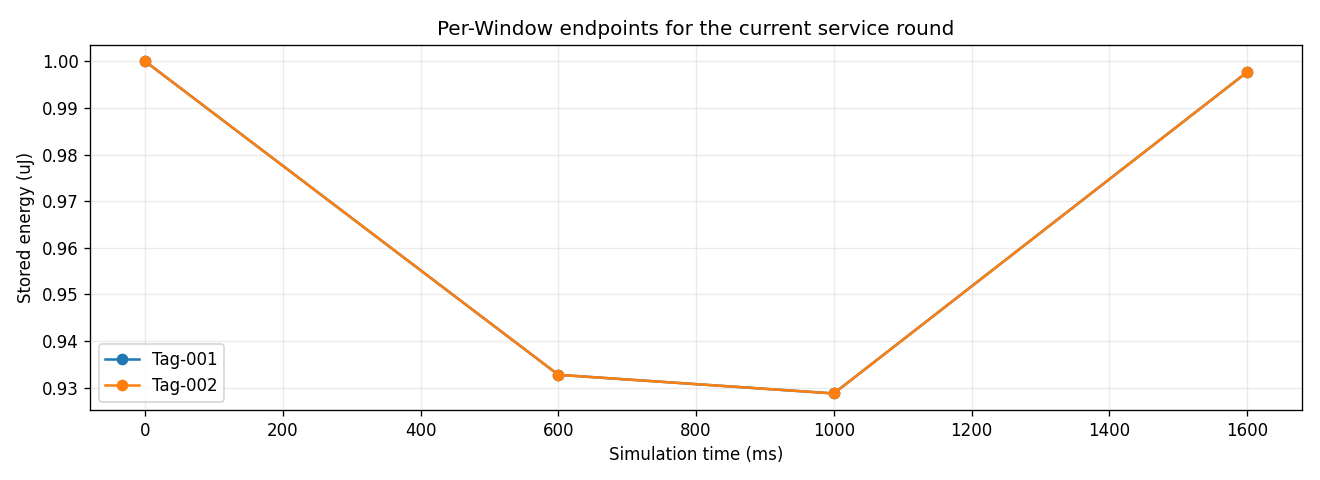

PASS: Window summaries consumed; current state retained; latest plot only


In [13]:
round_display = display('', display_id=True)


def consume_round(result):
    render_round(result, round_display)


final_snapshots = dict(engine.state.snapshots)
engine.finish_round(consume_round)
assert engine.records.window_summaries == []
assert engine.records.completion_batches == []
assert engine.records.trace == []
assert engine.state.snapshots == final_snapshots
assert all(snapshot.now_ns == 1_600_000_000 for snapshot in final_snapshots.values())
print('PASS: Window summaries consumed; current state retained; latest plot only')


## 6．本次 trace 範圍與檢查方式

先讀三組資料，再逐一閱讀準備函式；最後從 run_until 追查每個明確寫入位置。
核心計算的輸入／回傳值與引擎更新時間分開測試，並與重構前 18 個獨立觀察點比較。

已保留：整數 ns、同時事件順序、完整 TBS、儲能准入、失敗不退款、明確 CW 與跨窗電量。
尚待您人工逐段接受；執行與測試成功不代表可讀性或硬體模型已驗收。
本單元沒有正式 Access 排程、ServiceManager、FBL 抽樣、Policy／Baseline 或自動存檔。

- [完整程式 trace](../docs/architecture/event-engine/code-trace.md)
- [中文導讀](../docs/architecture/event-engine/README.zh-TW.md)
- [能量核心](../src/energy/tag_energy.py)
